#  Madrid Weather Data Engineering & ML Pipeline (PySpark)

##  Project Overview
This notebook implements an end-to-end **Medallion Architecture (Bronze, Silver, Gold)** and a **Machine Learning forecasting pipeline** using **Apache Spark (PySpark)**. The goal is to process over 100,000 hourly meteorological records, detect historical climate anomalies automatically, and predict short-term temperature trends.

##  Data Source & Metadata
* **Source:** Historical Meteorological Reanalysis Data via [Open-Meteo API](https://open-meteo.com/) / Madrid Weather Station.
* **Location:** Madrid, Spain (`Latitude: 40.3866° N`, `Longitude: -3.6761° W`).
* **Elevation:** 651.0 meters above sea level.
* **Timeframe:** January 1, 2015 – October 6, 2026 (Hourly resolution, `GMT+0`).
* **Total Records:** 103,128 observations across 14 meteorological variables (temperature, precipitation, snowfall, snow depth, relative humidity, sea-level pressure, WMO weather code, and cloud cover layers).

## (1) Bronze Layer (Raw Ingestion & Schema Enforcement)





**Metadata Stripping:** The original CSV file contains 3 header lines with station metadata (coordinates and elevation) before the actual tabular data starts on line 4. We strip these initial lines prior to ingestion.

In [104]:
with open("/content/TIEMPO_MADRID.csv", "r") as entrada:
    for _ in range(3):
        entrada.readline() #lee las primeras 3 lineas y las descarta

    with open("/content/tiempo_madrid_limpio.csv", "w") as salida:
        for linea in entrada:
            salida.write(linea) #escribe en un nuevo archivo las lineas restantes

print("New file: /content/tiempo_madrid_limpio.csv")

New file: /content/tiempo_madrid_limpio.csv


**Strict Schema (`StructType`):** Instead of using `inferSchema=True` (which requires an extra full read of the file and risks type mismatches in production), we enforce a strict schema upon ingestion.

In [105]:
from pyspark.sql.types import (StructType, StructField, StringType, DoubleType, IntegerType)

schema_clima = StructType([
    StructField("time", StringType(),False),#time as string
    StructField("temperature_2m", DoubleType(),True),#temperature in degrees celsius as float
    StructField("precipitation", DoubleType(),True),#precipitation in mm as float
    StructField("snowfall", DoubleType(),True),#snowfall in cm as float
    StructField("relative_humidity_2m", IntegerType(),True),#relative_humidity_2m in % as int
    StructField("rain", DoubleType(),True),#rain in mm as float
    StructField("snow_depth", DoubleType(),True),#snow_depth in m as float
    StructField("apparent_temperature", DoubleType(),True),#apparent_temperature in degrees celcius as float
    StructField("pressure_msl", DoubleType(),True),#sea-level pressure in hPa as float
    StructField("weather_code", IntegerType(),True),# weather code as int
    StructField("cloud_cover", IntegerType(),True),#cloud cover in % as int
    StructField("cloud_cover_low", IntegerType(),True),#cloud cover low in % as int
    StructField("cloud_cover_mid", IntegerType(),True),#cloud cover mid in % as int
    StructField("cloud_cover_high", IntegerType(),True)#cloud cover high in % as int
])

In [106]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("MiPrimeraAplicacion").getOrCreate()

In [107]:
df_raw = spark.read.option("header", "true").schema(schema_clima).csv("/content/tiempo_madrid_limpio.csv")

df_raw.printSchema()
df_raw.show(5)

root
 |-- time: string (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- snowfall: double (nullable = true)
 |-- relative_humidity_2m: integer (nullable = true)
 |-- rain: double (nullable = true)
 |-- snow_depth: double (nullable = true)
 |-- apparent_temperature: double (nullable = true)
 |-- pressure_msl: double (nullable = true)
 |-- weather_code: integer (nullable = true)
 |-- cloud_cover: integer (nullable = true)
 |-- cloud_cover_low: integer (nullable = true)
 |-- cloud_cover_mid: integer (nullable = true)
 |-- cloud_cover_high: integer (nullable = true)

+----------------+--------------+-------------+--------+--------------------+----+----------+--------------------+------------+------------+-----------+---------------+---------------+----------------+
|            time|temperature_2m|precipitation|snowfall|relative_humidity_2m|rain|snow_depth|apparent_temperature|pressure_msl|weather_code|cloud_cover|cloud_cover_

The date comes as text: "2015-01-01T00:00". We'll convert it to timestamp format and extract the year and month to organize the disk saving:

In [108]:
from pyspark.sql.functions import to_timestamp, year, month

df_bronze = df_raw \
    .withColumn("timestamp", to_timestamp("time", "yyyy-MM-dd'T'HH:mm")) \
    .withColumn("year", year("timestamp")) \
    .withColumn("month", month("timestamp"))

df_bronze.select("time", "timestamp", "year", "month", "temperature_2m").show(5)

+----------------+-------------------+----+-----+--------------+
|            time|          timestamp|year|month|temperature_2m|
+----------------+-------------------+----+-----+--------------+
|2015-01-01T00:00|2015-01-01 00:00:00|2015|    1|          -2.0|
|2015-01-01T01:00|2015-01-01 01:00:00|2015|    1|          -1.9|
|2015-01-01T02:00|2015-01-01 02:00:00|2015|    1|          -1.9|
|2015-01-01T03:00|2015-01-01 03:00:00|2015|    1|          -1.7|
|2015-01-01T04:00|2015-01-01 04:00:00|2015|    1|          -1.4|
+----------------+-------------------+----+-----+--------------+
only showing top 5 rows


**Partitioned Parquet Storage:** Data is converted from CSV to **Apache Parquet** partitioned by `year`, reducing storage footprint and enabling partition pruning for downstream queries.t

In [109]:
ruta_bronze = "data/bronze/weather_parquet"

df_bronze.write \
    .mode("overwrite") \
    .partitionBy("year") \
    .parquet(ruta_bronze)


## (2) Silver Layer (Data Cleansing & Feature Engineering)


In [110]:
df_bronze_read = spark.read.parquet("data/bronze/weather_parquet")

print(f"Total rows: {df_bronze_read.count()}")

Total rows: 103128


**Column Normalization:** Renamed raw column names to clean standard `snake_case` without special characters or unit symbols.

In [111]:
df_renamed = df_bronze_read \
    .withColumnRenamed("temperature_2m", "temperature_celsius") \
    .withColumnRenamed("apparent_temperature", "apparent_temperature_celsius") \
    .withColumnRenamed("precipitation", "precipitation_mm") \
    .withColumnRenamed("relative_humidity_2m", "relative_humidity_pct") \
    .withColumnRenamed("snowfall", "snowfall_cm") \
    .withColumnRenamed("snow_depth", "snow_depth_m") \
    .withColumnRenamed("rain", "rain_mm") \
    .withColumnRenamed("pressure_msl", "pressure_hpa") \
    .withColumnRenamed("weather_code", "weather_code") \
    .withColumnRenamed("cloud_cover", "cloud_cover_pct") \
    .withColumnRenamed("cloud_cover_low", "cloud_cover_low_pct") \
    .withColumnRenamed("cloud_cover_mid", "cloud_cover_mid_pct") \
    .withColumnRenamed("cloud_cover_high", "cloud_cover_high_pct") \
    .drop("time")
df_renamed.printSchema()

root
 |-- temperature_celsius: double (nullable = true)
 |-- precipitation_mm: double (nullable = true)
 |-- snowfall_cm: double (nullable = true)
 |-- relative_humidity_pct: integer (nullable = true)
 |-- rain_mm: double (nullable = true)
 |-- snow_depth_m: double (nullable = true)
 |-- apparent_temperature_celsius: double (nullable = true)
 |-- pressure_hpa: double (nullable = true)
 |-- weather_code: integer (nullable = true)
 |-- cloud_cover_pct: integer (nullable = true)
 |-- cloud_cover_low_pct: integer (nullable = true)
 |-- cloud_cover_mid_pct: integer (nullable = true)
 |-- cloud_cover_high_pct: integer (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- month: integer (nullable = true)
 |-- year: integer (nullable = true)



In [112]:
df_renamed.show(5)

+-------------------+----------------+-----------+---------------------+-------+------------+----------------------------+------------+------------+---------------+-------------------+-------------------+--------------------+-------------------+-----+----+
|temperature_celsius|precipitation_mm|snowfall_cm|relative_humidity_pct|rain_mm|snow_depth_m|apparent_temperature_celsius|pressure_hpa|weather_code|cloud_cover_pct|cloud_cover_low_pct|cloud_cover_mid_pct|cloud_cover_high_pct|          timestamp|month|year|
+-------------------+----------------+-----------+---------------------+-------+------------+----------------------------+------------+------------+---------------+-------------------+-------------------+--------------------+-------------------+-----+----+
|                4.5|             0.0|        0.0|                   73|    0.0|         0.0|                         0.3|      1032.7|           0|              0|                  0|                  0|                   0|2018

**Temporal Features:** Extracted calendar attributes (`month`, `day`, `hour`, `day_of_week`) and mapped meteorological seasons (`Winter`, `Spring`, `Summer`, `Autumn`).

In [113]:
from pyspark.sql.functions import col, dayofmonth, hour, dayofweek, when

df_features = df_renamed \
    .withColumn("day", dayofmonth("timestamp")) \
    .withColumn("hour", hour("timestamp")) \
    .withColumn("day_of_week", dayofweek("timestamp")) \
    .withColumn("seasons",
        when(col("month").isin(12, 1, 2), "Winter")
        .when(col("month").isin(3, 4, 5), "Spring")
        .when(col("month").isin(6, 7, 8), "Summer")
        .otherwise("Fall")
    )

df_features.select("timestamp", "year", "month", "day", "hour", "seasons").show(5)

+-------------------+----+-----+---+----+-------+
|          timestamp|year|month|day|hour|seasons|
+-------------------+----+-----+---+----+-------+
|2018-01-01 00:00:00|2018|    1|  1|   0| Winter|
|2018-01-01 01:00:00|2018|    1|  1|   1| Winter|
|2018-01-01 02:00:00|2018|    1|  1|   2| Winter|
|2018-01-01 03:00:00|2018|    1|  1|   3| Winter|
|2018-01-01 04:00:00|2018|    1|  1|   4| Winter|
+-------------------+----+-----+---+----+-------+
only showing top 5 rows


**Data Quality Rules:** Filtered out physically impossible sensor readings (e.g., relative humidity or cloud cover outside `0–100%`, temperatures outside `-25°C to 50°C`) and created binary flags for rain (`>= 0.1 mm`) and frost (`< 0°C`).

In [114]:
df_silver = df_features.filter(
        (col("temperature_celsius") >= -25.0) & (col("temperature_celsius") <= 50.0) &
        (col("relative_humidity_pct") >= 0) & (col("relative_humidity_pct") <= 100) &
        (col("cloud_cover_pct") >= 0) & (col("cloud_cover_pct") <= 100)
    ) \
    .withColumn("rain_flag", when(col("precipitation_mm") >= 0.1, 1).otherwise(0)) \
    .withColumn("frost_flag", when(col("temperature_celsius") < 0.0, 1).otherwise(0))

print(f"Total records: {df_silver.count()}")

Total records: 103128


In [115]:
df_silver.show(5)

+-------------------+----------------+-----------+---------------------+-------+------------+----------------------------+------------+------------+---------------+-------------------+-------------------+--------------------+-------------------+-----+----+---+----+-----------+-------+---------+----------+
|temperature_celsius|precipitation_mm|snowfall_cm|relative_humidity_pct|rain_mm|snow_depth_m|apparent_temperature_celsius|pressure_hpa|weather_code|cloud_cover_pct|cloud_cover_low_pct|cloud_cover_mid_pct|cloud_cover_high_pct|          timestamp|month|year|day|hour|day_of_week|seasons|rain_flag|frost_flag|
+-------------------+----------------+-----------+---------------------+-------+------------+----------------------------+------------+------------+---------------+-------------------+-------------------+--------------------+-------------------+-----+----+---+----+-----------+-------+---------+----------+
|                4.5|             0.0|        0.0|                   73|    0.0

**Storage:** Saved in Parquet format partitioned by `year` and `month`.

In [116]:
ruta_silver = "data/silver/weather_silver"

df_silver.write \
    .mode("overwrite") \
    .partitionBy("year", "month") \
    .parquet(ruta_silver)

## (3) Gold Layer (Business Aggregations & Time-Series Analytics)
In this layer, we build analytical tables and apply **PySpark Window Functions**:





In [117]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

df_silver = spark.read.parquet("data/silver/weather_silver")
print(f"Total rows: {df_silver.count()}")

Total rows: 103128


* **Daily Summary Table:** We generated a new table with key statistics per day: maximum, minimum, and average temperatures, total precipitation, total snowfall, maximum snow depth, hours of frost and rain, and the difference between maximum and minimum temperatures for each day.

In [118]:
df_daily = df_silver.groupBy("year", "month", "day", "seasons").agg(
    F.round(F.min("temperature_celsius"), 2).alias("t_min"),
    F.round(F.max("temperature_celsius"), 2).alias("t_max"),
    F.round(F.avg("temperature_celsius"), 2).alias("t_avg"),
    F.round(F.sum("precipitation_mm"), 2).alias("total_precip_mm"),
    F.round(F.sum("snowfall_cm"), 2).alias("total_snowfall_cm"),
    F.round(F.max("snow_depth_m"), 2).alias("max_snow_depth_m"),
    F.sum("frost_flag").alias("hores_frost"),
    F.sum("rain_flag").alias("hores_rain")
).withColumn(
    "temperature_range", F.round(F.col("t_max") - F.col("t_min"), 2)
)

df_daily = df_daily.withColumn(
    "date",
    F.to_date(F.concat_ws("-", "year", "month", "day"))
).orderBy("date")

df_daily.show(5)

+----+-----+---+-------+-----+-----+-----+---------------+-----------------+----------------+-----------+----------+-----------------+----------+
|year|month|day|seasons|t_min|t_max|t_avg|total_precip_mm|total_snowfall_cm|max_snow_depth_m|hores_frost|hores_rain|temperature_range|      date|
+----+-----+---+-------+-----+-----+-----+---------------+-----------------+----------------+-----------+----------+-----------------+----------+
|2015|    1|  1| Winter| -3.0|  9.1|  2.4|            0.0|              0.0|             0.0|         10|         0|             12.1|2015-01-01|
|2015|    1|  2| Winter| -3.4|  9.8|  2.3|            0.0|              0.0|             0.0|         11|         0|             13.2|2015-01-02|
|2015|    1|  3| Winter| -1.6|  9.7|  3.3|            0.0|              0.0|             0.0|          7|         0|             11.3|2015-01-03|
|2015|    1|  4| Winter| -1.8| 12.2| 4.12|            0.0|              0.0|             0.0|          9|         0|        

In [119]:
filas = df_daily.tail(5)

for fila in filas:
  print(fila)

Row(year=2026, month=10, day=2, seasons='Fall', t_min=15.4, t_max=23.8, t_avg=18.13, total_precip_mm=20.4, total_snowfall_cm=0.0, max_snow_depth_m=0.0, hores_frost=0, hores_rain=18, temperature_range=8.4, date=datetime.date(2026, 10, 2))
Row(year=2026, month=10, day=3, seasons='Fall', t_min=15.8, t_max=22.0, t_avg=18.34, total_precip_mm=5.2, total_snowfall_cm=0.0, max_snow_depth_m=0.0, hores_frost=0, hores_rain=12, temperature_range=6.2, date=datetime.date(2026, 10, 3))
Row(year=2026, month=10, day=4, seasons='Fall', t_min=15.1, t_max=21.7, t_avg=17.13, total_precip_mm=12.9, total_snowfall_cm=0.0, max_snow_depth_m=0.0, hores_frost=0, hores_rain=12, temperature_range=6.6, date=datetime.date(2026, 10, 4))
Row(year=2026, month=10, day=5, seasons='Fall', t_min=13.4, t_max=23.4, t_avg=17.63, total_precip_mm=3.4, total_snowfall_cm=0.0, max_snow_depth_m=0.0, hores_frost=0, hores_rain=4, temperature_range=10.0, date=datetime.date(2026, 10, 5))
Row(year=2026, month=10, day=6, seasons='Fall', t_

* **Moving Averages (`Window.rowsBetween`):** To identify whether a day or a week in general was colder or warmer than another, moving averages can be used.

In [120]:

#(24h)
window_24h = Window.orderBy("timestamp").rowsBetween(-23, 0)

#(7 * 24 = 168 hores)
window_7d = Window.orderBy("timestamp").rowsBetween(-167, 0)

df_hourly_trends = df_silver.withColumn(
    "temp_ma_24h", F.round(F.avg("temperature_celsius").over(window_24h), 2)
).withColumn(
    "temp_ma_7d", F.round(F.avg("temperature_celsius").over(window_7d), 2)
)

df_hourly_trends.select(
    "timestamp", "temperature_celsius", "temp_ma_24h", "temp_ma_7d"
).show(15)

+-------------------+-------------------+-----------+----------+
|          timestamp|temperature_celsius|temp_ma_24h|temp_ma_7d|
+-------------------+-------------------+-----------+----------+
|2015-01-01 00:00:00|               -2.0|       -2.0|      -2.0|
|2015-01-01 01:00:00|               -1.9|      -1.95|     -1.95|
|2015-01-01 02:00:00|               -1.9|      -1.93|     -1.93|
|2015-01-01 03:00:00|               -1.7|      -1.88|     -1.88|
|2015-01-01 04:00:00|               -1.4|      -1.78|     -1.78|
|2015-01-01 05:00:00|               -1.5|      -1.73|     -1.73|
|2015-01-01 06:00:00|               -1.6|      -1.71|     -1.71|
|2015-01-01 07:00:00|               -2.3|      -1.79|     -1.79|
|2015-01-01 08:00:00|               -3.0|      -1.92|     -1.92|
|2015-01-01 09:00:00|               -0.8|      -1.81|     -1.81|
|2015-01-01 10:00:00|                3.1|      -1.36|     -1.36|
|2015-01-01 11:00:00|                6.0|      -0.75|     -0.75|
|2015-01-01 12:00:00|    


* **Detection of Real Case Studies:** Rather than hardcoding dates, we query extreme statistical outliers in snowfall accumulation and sub-zero temperatures, automatically isolating **Storm Filomena (January 2021)**—where Madrid recorded a historic **20.16 cm** daily snowfall followed by a minimum temperature of **-11.1 °C**.


# CASE A: The historical impact of Storm Filomena (January 2021)

We filtered the days with the greatest accumulation of snow and extreme cold recorded in the last decade in Madrid

In [121]:
top_nevadas = df_daily.filter(F.col("total_snowfall_cm") > 0) \
    .orderBy(F.desc("total_snowfall_cm"))

print("--- Top historical snow events detected ---")
top_nevadas.select("date", "total_snowfall_cm", "max_snow_depth_m", "t_min", "t_max").show(5)

--- Top historical snow events detected ---
+----------+-----------------+----------------+-----+-----+
|      date|total_snowfall_cm|max_snow_depth_m|t_min|t_max|
+----------+-----------------+----------------+-----+-----+
|2021-01-09|            20.16|            0.24| -1.4|  0.6|
|2021-01-08|            12.25|             0.1| -1.7|  1.4|
|2026-01-28|             4.27|            0.03|  1.4|  8.7|
|2020-03-31|             3.92|            0.02|  1.2| 10.9|
|2026-02-04|             2.66|            0.02|  2.8| 10.0|
+----------+-----------------+----------------+-----+-----+
only showing top 5 rows


We see that the days with the most snowfall in the last decade were those of Storm Filomena in January 2021. Once we know this, we will represent them in a graph between 2021-01-05 and 2021-02-10.

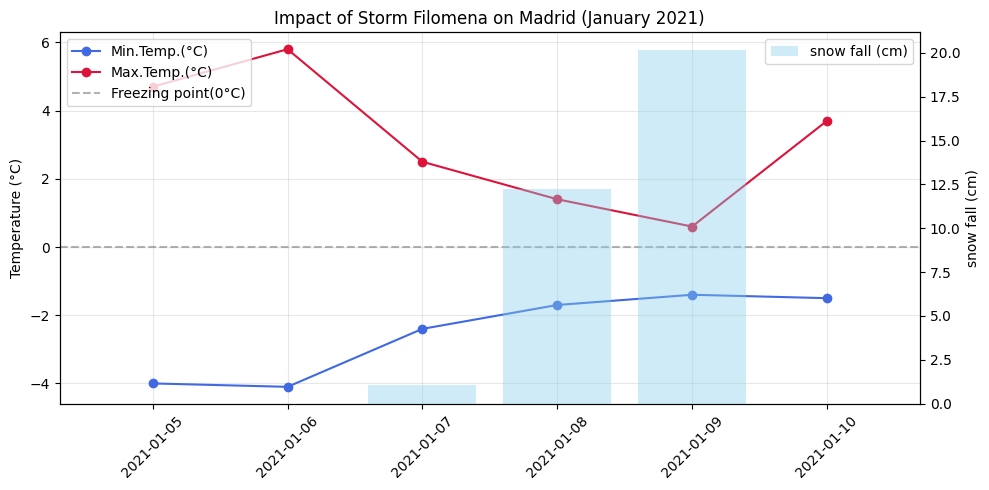

In [122]:
import matplotlib.pyplot as plt

filomena_event =df_daily.filter((F.col("year") == 2021) & (F.col("month") == 1) & (F.col("day").between(5, 10))).orderBy("date")

#to pandas
df_filomena_pd =filomena_event.toPandas()
fig, ax1 =plt.subplots(figsize=(10, 5))

#x-AXIS:Temperaturas
ax1.plot(df_filomena_pd["date"], df_filomena_pd["t_min"], color="royalblue", marker="o", label="Min.Temp.(°C)")
ax1.plot(df_filomena_pd["date"], df_filomena_pd["t_max"], color="crimson", marker="o", label="Max.Temp.(°C)")
ax1.axhline(0, color="gray", linestyle="--", alpha=0.6, label="Freezing point(0°C)")
ax1.set_ylabel("Temperature (°C)")
ax1.set_title("Impact of Storm Filomena on Madrid (January 2021)")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

#y-AXIS:snow accumulation
ax2=ax1.twinx()
ax2.bar(df_filomena_pd["date"], df_filomena_pd["total_snowfall_cm"], color="skyblue", alpha=0.4, label="snow fall (cm)")
ax2.set_ylabel("snow fall (cm)")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# CASE B: Days of extreme heat (maximum temperature ≥ 38ºC)

In [123]:
dias_calor_extremo = df_daily.filter(F.col("t_max") >= 38.0).orderBy(F.desc("t_max"))

print(f"Total days with temperature >= 38°C: {dias_calor_extremo.count()}")
dias_calor_extremo.select("date", "t_min", "t_max", "temperature_range", "seasons").show(10)

Total days with temperature >= 38°C: 103
+----------+-----+-----+-----------------+-------+
|      date|t_min|t_max|temperature_range|seasons|
+----------+-----+-----+-----------------+-------+
|2021-08-13| 21.2| 41.5|             20.3| Summer|
|2022-07-14| 24.5| 41.3|             16.8| Summer|
|2025-08-16| 24.2| 40.7|             16.5| Summer|
|2024-07-24| 24.2| 40.4|             16.2| Summer|
|2019-06-28| 22.4| 40.3|             17.9| Summer|
|2017-07-13| 20.8| 40.3|             19.5| Summer|
|2025-06-29| 24.6| 40.3|             15.7| Summer|
|2022-07-18| 24.1| 40.3|             16.2| Summer|
|2021-08-15| 22.5| 40.2|             17.7| Summer|
|2021-08-14| 24.4| 40.2|             15.8| Summer|
+----------+-----+-----+-----------------+-------+
only showing top 10 rows


In [124]:
ruta_gold_daily = "data/gold/weather_daily_summary"

df_daily.write \
    .mode("overwrite") \
    .parquet(ruta_gold_daily)

## (4) Predictive Modeling with Spark MLlib


**Lag Feature Engineering:** Using `F.lag()` over a chronological window, we feed the model with historical inertia ($t-1$, $t-2$, and $t-24$ temperatures, plus lagged humidity and atmospheric pressure).

In [125]:
df_silver = spark.read.parquet("data/silver/weather_silver")

w = Window.orderBy("timestamp") #ORDERBY date


df_ml_prep = df_silver \
    .withColumn("temp_lag_1", F.lag("temperature_celsius", 1).over(w)) \
    .withColumn("temp_lag_2", F.lag("temperature_celsius", 2).over(w)) \
    .withColumn("temp_lag_24", F.lag("temperature_celsius", 24).over(w)) \
    .withColumn("humidity_lag_1", F.lag("relative_humidity_pct", 1).over(w)) \
    .withColumn("pressure_lag_1", F.lag("pressure_hpa", 1).over(w)) \
    .dropna()  #The first 24 rows will contain nulls due to the 24-hour lag


**Temporal Train/Test Split:** To prevent *data leakage*, we use a strict chronological split:
  * **Training Set:** 2015 – 2023
  * **Testing Set:** 2024 – 2026

In [126]:
train_df = df_ml_prep.filter(F.col("year") <= 2023)
test_df = df_ml_prep.filter(F.col("year") >= 2024)

print(f"Train rows: {train_df.count()}")
print(f"Test rows: {test_df.count()}")

Train rows: 78864
Test rows: 24240


**ML Pipeline:** `VectorAssembler` $\rightarrow$ `StandardScaler` $\rightarrow$ `LinearRegression`.

In [127]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml import Pipeline

#predictor variables
feature_cols =["hour", "month", "day_of_week", "temp_lag_1", "temp_lag_2", "temp_lag_24", "humidity_lag_1", "pressure_lag_1"]

#VectorAssembler:
assembler =VectorAssembler(inputCols=feature_cols, outputCol="raw_features")

#Escaler
scaler =StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)

#Regression model
lr =LinearRegression(featuresCol="features", labelCol="temperature_celsius", maxIter=50, regParam=0.01)

#Pipeline
ml_pipeline =Pipeline(stages=[assembler, scaler, lr])

#Train
modelo_entrenado = ml_pipeline.fit(train_df)
print("trained model!")

trained model!


In [128]:
from pyspark.ml.evaluation import RegressionEvaluator

#Generate predictions on the test set
predicciones = modelo_entrenado.transform(test_df)

#Metrics Evaluator
evaluador_rmse = RegressionEvaluator(labelCol="temperature_celsius", predictionCol="prediction", metricName="rmse")
evaluador_mae = RegressionEvaluator(labelCol="temperature_celsius", predictionCol="prediction", metricName="mae")
evaluador_r2 = RegressionEvaluator(labelCol="temperature_celsius", predictionCol="prediction", metricName="r2")

rmse_val = evaluador_rmse.evaluate(predicciones)
mae_val = evaluador_mae.evaluate(predicciones)
r2_val = evaluador_r2.evaluate(predicciones)

print(f"--- RESULTS ON THE TEST SET ---")
print(f"RMSE (Mean squared error): {rmse_val:.2f} °C")
print(f"MAE  (Mean absolute error):   {mae_val:.2f} °C")
print(f"R²   (Coefficient of determination): {r2_val:.3f}")

--- RESULTS ON THE TEST SET ---
RMSE (Mean squared error): 0.77 °C
MAE  (Mean absolute error):   0.56 °C
R²   (Coefficient of determination): 0.993


**Performance:** Achieved an $R^2 > 0.99$ and a Mean Absolute Error of **~0.56 °C** on unseen test data

We conducted a 7-day trial comparing the real thing with the model.

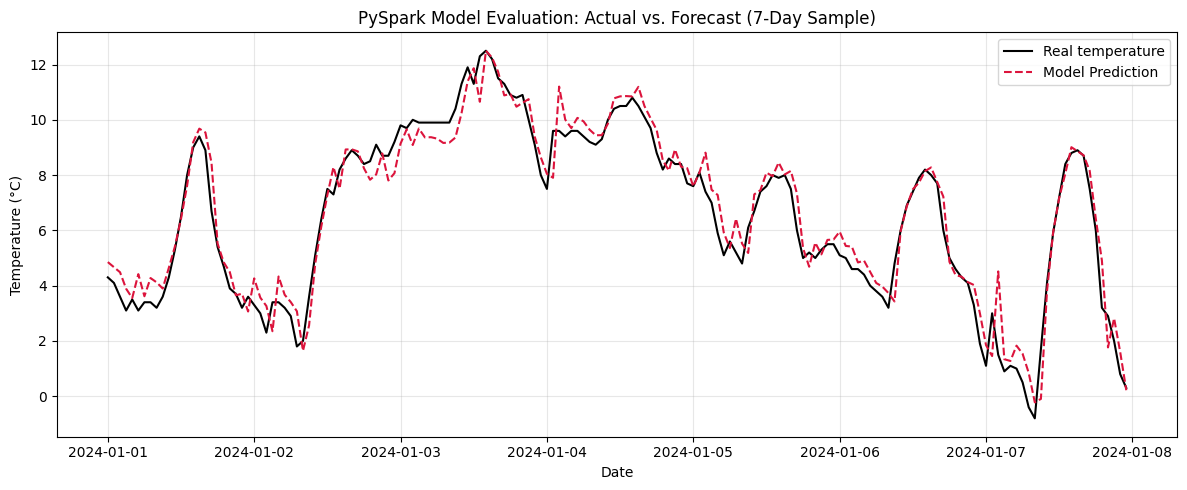

In [129]:
#7 days (168 hores)
muestra_pred = predicciones.orderBy("timestamp").limit(168).select("timestamp", "temperature_celsius", "prediction").toPandas()

plt.figure(figsize=(12, 5))
plt.plot(muestra_pred["timestamp"], muestra_pred["temperature_celsius"], label="Real temperature", color="black", linewidth=1.5)
plt.plot(muestra_pred["timestamp"], muestra_pred["prediction"], label="Model Prediction", color="crimson", linestyle="--", linewidth=1.5)

plt.title("PySpark Model Evaluation: Actual vs. Forecast (7-Day Sample)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## (5) Automated Unit Testing & Documentation Export


In [130]:
import os
os.makedirs("tests", exist_ok=True)
print("Folder 'tests/' created successfully")

Folder 'tests/' created successfully


We created two test functions:


The first one creates a minimal table of only 4 rows with one month for each season: (1, "January"), (4, "April"), (7, "July") and (10, "October"). It converts the Spark result to a Python dictionary called seasons, which looks like this: {1: 'Winter', 4: 'Spring', 7: 'Summer', 10: 'Autumn'}. If what is to its right is True (seasons[1] == "Winter"), the test passes.

-----------------------------------------------------------------


The second test function creates trap data:

It creates a DataFrame with 3 rows: Row 1: (-30.0, 50) -> Trap: temperature of -30 °C (outside the allowed limit of -25 °C).

Row 2: (20.0, 120) -> Trap: humidity of 120% (physically impossible, the maximum is 100%).

Row 3: (15.0, 65) -> Valid data: 15 °C and 65% humidity.

assert df_valid.count() == 1: Checks that only one row survived (the two trap rows must have been removed).


In [131]:
%%writefile tests/test_transforms.py
import pytest
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, IntegerType

@pytest.fixture(scope="session")
def spark():
    return SparkSession.builder \
        .appName("PySparkUnitTests") \
        .master("local[2]") \
        .getOrCreate()

def test_enriquecimiento_estaciones(spark):
    """Verifica que la asignación de estaciones sea correcta según el mes."""
    data = [(1, "January"), (4, "April"), (7, "July"), (10, "October")]
    schema = StructType([
        StructField("month", IntegerType(), False),
        StructField("month_name", StringType(), False)
    ])
    df = spark.createDataFrame(data, schema)

    df_result = df.withColumn(
        "seasons",
        F.when(F.col("month").isin(12, 1, 2), "Winter")
        .when(F.col("month").isin(3, 4, 5), "Spring")
        .when(F.col("month").isin(6, 7, 8), "Summer")
        .otherwise("Fall")
    )

    estaciones = {row["month"]: row["seasons"] for row in df_result.collect()}
    assert estaciones[1] == "Winter"
    assert estaciones[4] == "Spring"
    assert estaciones[7] == "Summer"
    assert estaciones[10] == "Fall"

def test_reglas_calidad_limites(spark):
    """Verifica que el filtro descarte valores físicamente imposibles."""
    data = [(-30.0, 50), (20.0, 120), (15.0, 65)]  #row 1 invalid temp, row 2 invalid humidity
    schema = StructType([
        StructField("temperature_celsius", DoubleType(), False),
        StructField("relative_humidity_pct", IntegerType(), False)
    ])
    df = spark.createDataFrame(data, schema)

    df_valid = df.filter(
        (F.col("temperature_celsius") >= -25.0) & (F.col("temperature_celsius") <= 50.0) &
        (F.col("relative_humidity_pct") >= 0) & (F.col("relative_humidity_pct") <= 100)
    )

    assert df_valid.count() == 1
    assert df_valid.first()["temperature_celsius"] == 15.0

Overwriting tests/test_transforms.py


we run the tests

In [102]:
!pytest tests/test_transforms.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.12.2, anyio-4.15.1, langsmith-0.14.2, typeguard-4.6.0
collected 2 items                                                              

tests/test_transforms.py::test_enriquecimiento_estaciones PASSED         [ 50%]
tests/test_transforms.py::test_reglas_calidad_limites PASSED             [100%]

============================== 2 passed in 21.16s ==============================


# Export Graphics to the Repository

In [103]:
import os

os.makedirs("docs/img", exist_ok=True)

#Filomena
fig_filomena, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_filomena_pd["date"], df_filomena_pd["t_min"], color="royalblue", marker="o", label="Min.Temp.(°C)")
ax1.plot(df_filomena_pd["date"], df_filomena_pd["t_max"], color="crimson", marker="o", label="Max.Temp.(°C)")
ax1.axhline(0, color="gray", linestyle="--", alpha=0.6, label="Freezing point(0°C)")
ax1.set_ylabel("Temperature (°C)")
ax1.set_title("Impact of Storm Filomena on Madrid (January 2021)")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)


ax2=ax1.twinx()
ax2.bar(df_filomena_pd["date"], df_filomena_pd["total_snowfall_cm"], color="skyblue", alpha=0.4, label="snow fall (cm)")
ax2.set_ylabel("snow fall (cm)")
ax2.legend(loc="upper right")
plt.tight_layout()
fig_filomena.savefig("docs/img/filomena_impact.png", dpi=300)
plt.close(fig_filomena)

#predicciones
fig_ml, ax_ml = plt.subplots(figsize=(11, 4))
ax_ml.plot(muestra_pred["timestamp"], muestra_pred["temperature_celsius"], label="Real temperature", color="black", linewidth=1.5)
ax_ml.plot(muestra_pred["timestamp"], muestra_pred["prediction"], label="Model Prediction", color="crimson", linestyle="--", linewidth=1.5)

ax_ml.set_title("PySpark Model Evaluation: Actual vs. Forecast (7-Day Sample)")
ax_ml.set_xlabel("Date")
ax_ml.set_ylabel("Temperature (°C)")
ax_ml.legend()
ax_ml.grid(alpha=0.3)
plt.tight_layout()
fig_ml.savefig("docs/img/mllib_predictions.png", dpi=300)
plt.close(fig_ml)



print("Graphics exported successfully in docs/img/")

Graphics exported successfully in docs/img/
